# Question 2: Road Traffic Accident Severity

## Stage 3: Exploratory Data Analysis and Data Quality Audit

Group: Group 2

Members: Armand Ikirezi and Mariam Nyirarukundo

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

project_dir = Path(r"D:\MYProject\ML_Element1")

raw_path = (
    project_dir
    / "q2_own_scenario"
    / "data"
    / "raw"
    / "rwanda_traffic_accidents_synthetic.csv"
)

df = pd.read_csv(raw_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1608, 13)


,accident_id,district,road_type,weather,road_surface,lighting,time_of_day,vehicle_type,speed_limit_kmh,vehicles_involved,road_users_affected,response_time_min,severity
0,RWACC-00001,Rusizi,Market road,Rain,Dry,Dark,Afternoon,Car,60,2,2,10.1,Serious
1,RWACC-00002,Karongi,Highway,Clear,Damaged,Daylight,Morning,Car,100,2,4,27.6,Serious
2,RWACC-00003,Rubavu,Highway,Clear,Gravel,Daylight,Morning,Car,50,1,1,19.5,Minor
3,RWACC-00004,Kicukiro,Urban,Clear,Wet,Dark,Evening,Bus,30,2,1,28.2,Serious
4,RWACC-00005,Rusizi,Market road,NaN,Dry,Dark,Night,Truck,40,1,2,9.2,Fatal


In [2]:

print("DATASET SHAPE:", df.shape)

print("\nDATA TYPES")
print(df.dtypes)

print("\nDATASET INFO")
df.info()

print("\nSUMMARY STATISTICS")
display(df.describe(include="all").T)


DATASET SHAPE: (1608, 13)

DATA TYPES
accident_id                str
district                   str
road_type                  str
weather                    str
road_surface               str
lighting                   str
time_of_day                str
vehicle_type               str
speed_limit_kmh          int64
vehicles_involved        int64
road_users_affected      int64
response_time_min      float64
severity                   str
dtype: object

DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 1608 entries, 0 to 1607
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   accident_id          1608 non-null   str    
 1   district             1608 non-null   str    
 2   road_type            1608 non-null   str    
 3   weather              1567 non-null   str    
 4   road_surface         1576 non-null   str    
 5   lighting             1608 non-null   str    
 6   time_of_day          1608 non-

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
accident_id,1608,1600,RWACC-00001,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,1608,13,Kicukiro,159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
road_type,1608,5,Urban,668,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather,1567,4,Clear,1041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
road_surface,1576,4,Dry,973,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lighting,1608,3,Daylight,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_of_day,1608,4,Afternoon,520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,1608,6,Motorcycle,559,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speed_limit_kmh,1608.0,NaN,NaN,NaN,53.91791,20.44187,0.0,40.0,50.0,60.0,250.0
vehicles_involved,1608.0,NaN,NaN,NaN,1.800995,0.977124,1.0,1.0,2.0,2.0,5.0


In [3]:

missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(df) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report["Missing_Count"] > 0
    ]
)


,Missing_Count,Missing_Percentage
weather,41,2.55
road_surface,32,1.99
response_time_min,24,1.49


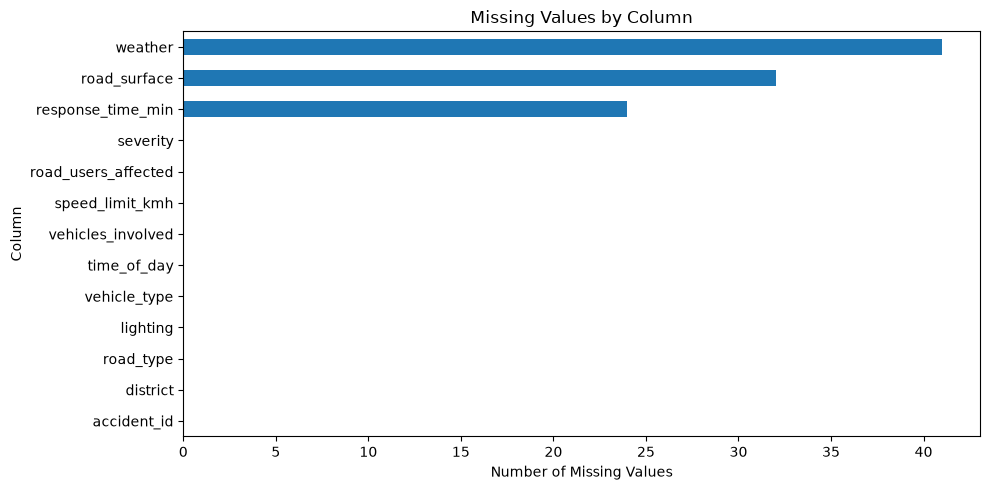

In [4]:

missing_report["Missing_Count"].sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


In [5]:

print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate accident IDs:",
    df["accident_id"].duplicated().sum()
)

display(df[df.duplicated(keep=False)].head(20))


Exact duplicate rows: 8
Duplicate accident IDs: 8


,accident_id,district,road_type,weather,road_surface,lighting,time_of_day,vehicle_type,speed_limit_kmh,vehicles_involved,road_users_affected,response_time_min,severity
0,RWACC-00001,Rusizi,Market road,Rain,Dry,Dark,Afternoon,Car,60,2,2,10.1,Serious
1,RWACC-00002,Karongi,Highway,Clear,Damaged,Daylight,Morning,Car,100,2,4,27.6,Serious
2,RWACC-00003,Rubavu,Highway,Clear,Gravel,Daylight,Morning,Car,50,1,1,19.5,Minor
3,RWACC-00004,Kicukiro,Urban,Clear,Wet,Dark,Evening,Bus,30,2,1,28.2,Serious
4,RWACC-00005,Rusizi,Market road,NaN,Dry,Dark,Night,Truck,40,1,2,9.2,Fatal
5,RWACC-00006,Musanze,Highway,Clear,Dry,Daylight,Afternoon,Car,40,1,1,24.1,Minor
6,RWACC-00007,Nyagatare,Urban,Clear,Wet,Dark,Afternoon,Motorcycle,40,1,2,14.0,Serious
7,RWACC-00008,Karongi,Rural,Rain,Dry,Daylight,Afternoon,Motorcycle,40,1,2,18.4,Serious
1600,RWACC-00001,Rusizi,Market road,Rain,Dry,Dark,Afternoon,Car,60,2,2,10.1,Serious
1601,RWACC-00002,Karongi,Highway,Clear,Damaged,Daylight,Morning,Car,100,2,4,27.6,Serious


In [6]:

categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))



accident_id
accident_id
RWACC-00001    2
RWACC-00002    2
RWACC-00003    2
RWACC-00004    2
RWACC-00005    2
              ..
RWACC-01596    1
RWACC-01597    1
RWACC-01598    1
RWACC-01599    1
RWACC-01600    1
Name: count, Length: 1600, dtype: int64

district
district
Kicukiro      159
Nyagatare     154
Huye          147
Muhanga       142
Karongi       141
Rusizi        136
Rwamagana     136
Musanze       132
Rubavu        118
Nyarugenge    116
Bugesera      111
Gasabo        110
Gasabo          6
Name: count, dtype: int64

road_type
road_type
Urban          668
Rural          485
Highway        291
Market road    158
High way         6
Name: count, dtype: int64

weather
weather
Clear    1041
Rain      356
Fog       113
Windy      57
NaN        41
Name: count, dtype: int64

road_surface
road_surface
Dry        973
Wet        288
Gravel     188
Damaged    127
NaN         32
Name: count, dtype: int64

lighting
lighting
Daylight         935
Street lights    392
Dark             281
Name

In [7]:

numerical_columns = df.select_dtypes(
    include=["number"]
).columns

outlier_report = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_report.append({
        "Column": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers)
    })

outlier_report = pd.DataFrame(outlier_report)

display(outlier_report)


,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,speed_limit_kmh,10.00,90.00,84
1,vehicles_involved,-0.50,3.50,115
2,road_users_affected,-2.50,9.50,0
3,response_time_min,-12.75,44.45,48


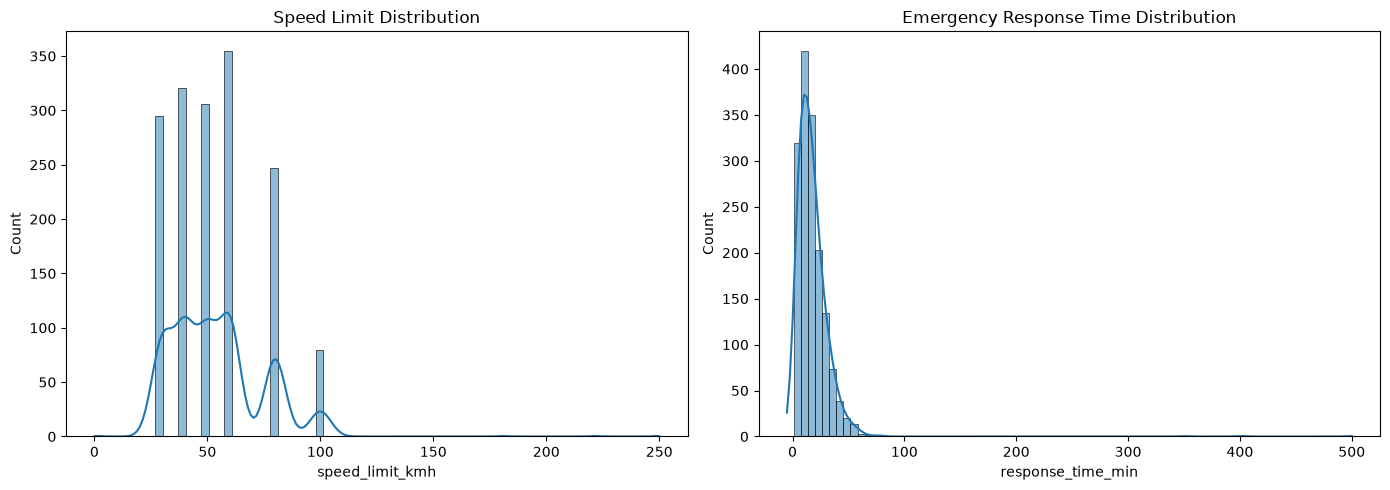

In [8]:

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5)
)

sns.histplot(
    data=df,
    x="speed_limit_kmh",
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Speed Limit Distribution")

sns.histplot(
    data=df,
    x="response_time_min",
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Emergency Response Time Distribution")

plt.tight_layout()
plt.show()


severity
Minor      901
Serious    639
Fatal       68
Name: count, dtype: int64

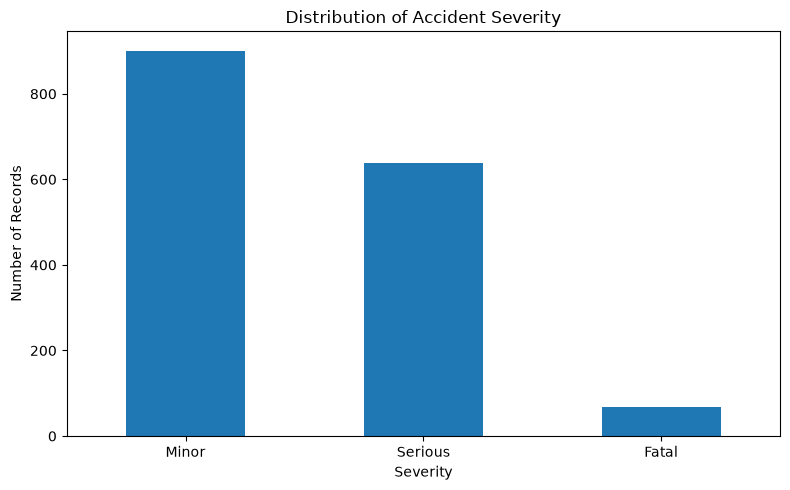

In [9]:

target_counts = df["severity"].value_counts()

display(target_counts)

target_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Accident Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


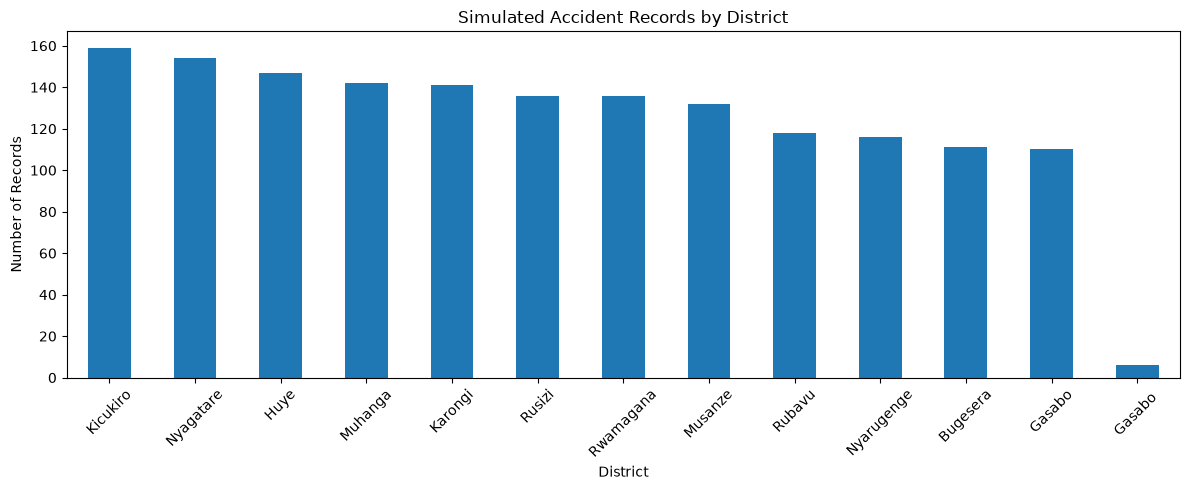

In [10]:

df["district"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Simulated Accident Records by District")
plt.xlabel("District")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


severity,Fatal,Minor,Serious
road_type,,,
High way,0,5,1
Highway,22,117,152
Market road,6,98,54
Rural,12,303,170
Urban,28,378,262


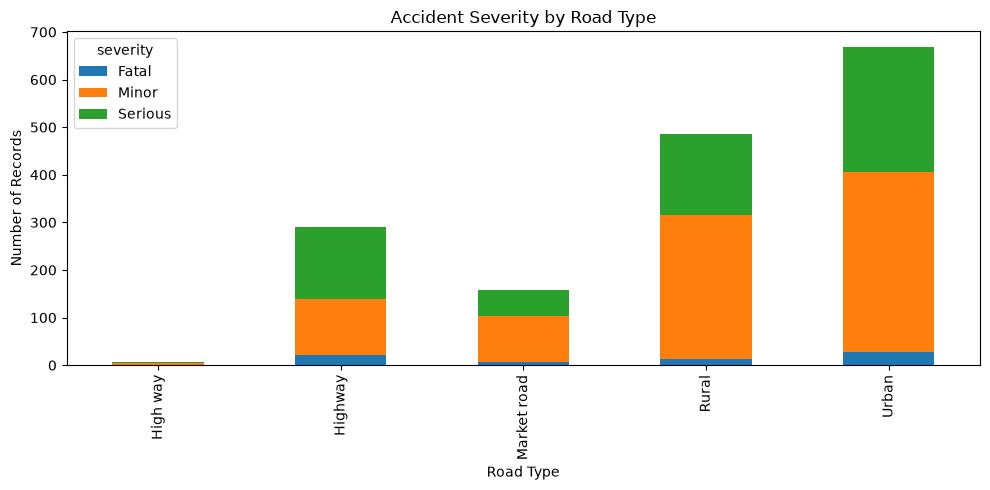

In [11]:

severity_road = pd.crosstab(
    df["road_type"],
    df["severity"]
)

display(severity_road)

severity_road.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Accident Severity by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


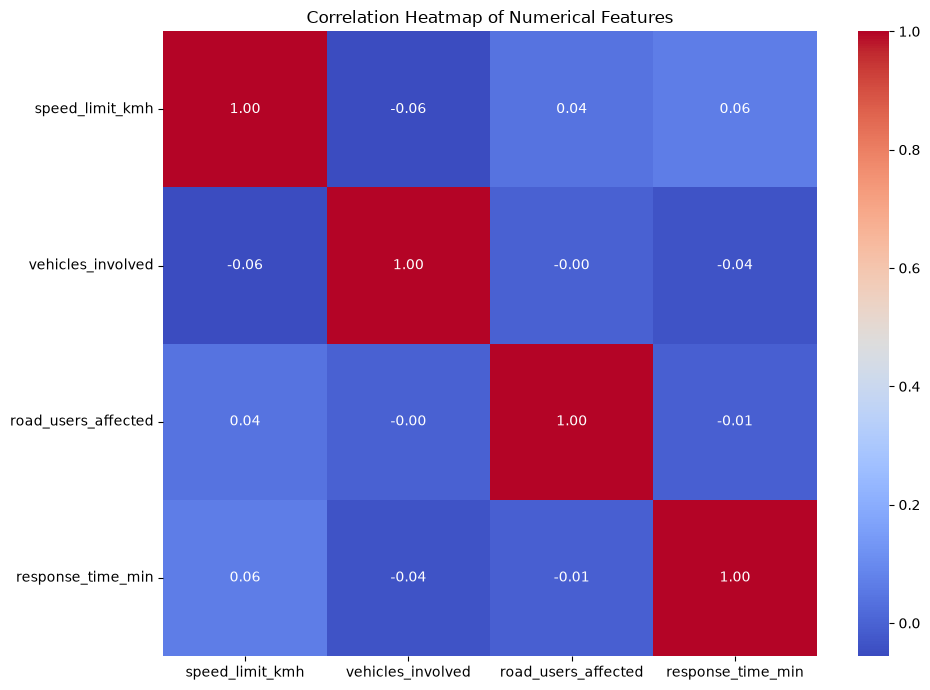

In [12]:

numeric_df = df.select_dtypes(
    include=["number"]
)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [13]:

quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2).values,
    "Unique_Values": df.nunique().values
})

quality_report.to_csv(
    project_dir
    / "q2_own_scenario"
    / "docs"
    / "data_quality_report.csv",
    index=False
)

display(quality_report)


,Column,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,accident_id,str,0,0.00,1600
1,district,str,0,0.00,13
2,road_type,str,0,0.00,5
3,weather,str,41,2.55,4
4,road_surface,str,32,1.99,4
5,lighting,str,0,0.00,3
6,time_of_day,str,0,0.00,4
7,vehicle_type,str,0,0.00,6
8,speed_limit_kmh,int64,0,0.00,10
9,vehicles_involved,int64,0,0.00,5
